# CW1: Cloud AI Framework for Credit Card Fraud Detection
## Notebook 2: Model Training, Evaluation and Explainability

This notebook covers the model training and tuning stage of the AI lifecycle. It trains supervised and unsupervised models on the preprocessed data from Notebook 1, compares them using metrics suited to imbalanced data, tunes the decision threshold, explains the best model with SHAP, and saves it for deployment to Azure Machine Learning.

---

### 1. Environment Setup and Data Loading

This step imports the modelling libraries, fixes the random seed, and loads the processed training and test sets saved in Notebook 1. The test set stays untouched until final evaluation; model selection uses cross-validation on the training set only.

In [1]:
import os
import sys
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
import xgboost as xgb
import imblearn
import shap

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Reproducibility and paths
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
FIG_DIR = "figures"
MODEL_DIR = "models"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# Chart style consistent with Notebook 1
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", "{:.4f}".format)

# Load processed data from Notebook 1
train = pd.read_csv(os.path.join("data", "processed", "train.csv"))
test = pd.read_csv(os.path.join("data", "processed", "test.csv"))

X_train, y_train = train.drop(columns="Class"), train["Class"]
X_test, y_test = test.drop(columns="Class"), test["Class"]
FEATURES = X_train.columns.tolist()

print(f"xgboost:          {xgb.__version__}")
print(f"imbalanced-learn: {imblearn.__version__}")
print(f"shap:             {shap.__version__}")
print(f"scikit-learn:     {sklearn.__version__}")
print(f"\nTraining set: {X_train.shape[0]:,} rows x {X_train.shape[1]} features, "
      f"{y_train.sum()} fraud ({y_train.mean()*100:.4f}%)")
print(f"Test set:     {X_test.shape[0]:,} rows x {X_test.shape[1]} features, "
      f"{y_test.sum()} fraud ({y_test.mean()*100:.4f}%)")
print(f"\nFeatures match between sets: {FEATURES == X_test.columns.tolist()}")

xgboost:          3.2.0
imbalanced-learn: 0.13.0
shap:             0.50.0
scikit-learn:     1.6.1

Training set: 226,980 rows x 31 features, 378 fraud (0.1665%)
Test set:     56,746 rows x 31 features, 95 fraud (0.1674%)

Features match between sets: True


### 2. Evaluation Framework and Baseline Model

This step defines how every model is compared, then trains the baseline.

**Evaluation method:** 5-fold stratified cross-validation on the training set. Each fold keeps the 0.17% fraud rate, and the standard deviation across folds shows how stable each model is.

**Metrics:**
- **PR-AUC (average precision)** is the primary metric. It summarises precision and recall across all thresholds and is not inflated by the large number of legitimate transactions (Saito and Rehmsmeier, 2015).
- **ROC-AUC** is reported for comparison with published work, but it looks optimistic on imbalanced data.
- **Precision, recall and F1** at the default 0.5 threshold show the operational trade-off: recall is the share of fraud caught, precision is the share of alerts that are real fraud.

**Baseline:** logistic regression, trained twice, without and with class weighting (`class_weight="balanced"`), which makes each fraud case count about 600 times more than a legitimate one during training.

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc",
           "Precision": "precision", "Recall": "recall", "F1": "f1"}
cv_results = []   # collects every model's scores for the final comparison


def evaluate_cv(name, model):
    """Run 5-fold stratified CV, print mean ± std for each metric, store results."""
    start = time.time()
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    elapsed = time.time() - start
    row = {"Model": name}
    for metric in SCORING:
        values = scores[f"test_{metric}"]
        row[metric] = values.mean()
        row[f"{metric}_std"] = values.std()
    row["CV time (s)"] = elapsed
    cv_results.append(row)
    summary = "  ".join(f"{m}: {row[m]:.3f} ± {row[m + '_std']:.3f}" for m in SCORING)
    print(f"{name}\n  {summary}\n  ({elapsed:.1f} s)\n")
    return row


# Baseline 1: logistic regression, no imbalance handling
evaluate_cv("Logistic Regression",
            LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

# Baseline 2: logistic regression with class weighting
evaluate_cv("Logistic Regression (balanced)",
            LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=RANDOM_STATE));

Logistic Regression
  PR-AUC: 0.756 ± 0.030  ROC-AUC: 0.974 ± 0.016  Precision: 0.870 ± 0.020  Recall: 0.611 ± 0.050  F1: 0.716 ± 0.030
  (3.2 s)

Logistic Regression (balanced)
  PR-AUC: 0.756 ± 0.027  ROC-AUC: 0.979 ± 0.010  Precision: 0.057 ± 0.005  Recall: 0.907 ± 0.036  F1: 0.108 ± 0.009
  (4.6 s)



### 3. Random Forest

This step trains a random forest, an ensemble of 100 decision trees, each built on a bootstrap sample of the data. Averaging many trees reduces variance and captures non-linear interactions between features that logistic regression cannot. Tree depth is capped at 12 to limit overfitting to the small fraud class and to keep training time manageable.

Two versions are compared: one without imbalance handling, and one with `class_weight="balanced_subsample"`, which reweights the fraud class within each tree's bootstrap sample.

In [4]:
from sklearn.ensemble import RandomForestClassifier

# Random forest without imbalance handling
evaluate_cv("Random Forest",
            RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1,
                                random_state=RANDOM_STATE))

# Random forest with class weighting per bootstrap sample
evaluate_cv("Random Forest (balanced)",
            RandomForestClassifier(n_estimators=100, max_depth=12,
                                class_weight="balanced_subsample", n_jobs=-1,
                                random_state=RANDOM_STATE));

Random Forest
  PR-AUC: 0.836 ± 0.028  ROC-AUC: 0.976 ± 0.012  Precision: 0.942 ± 0.019  Recall: 0.767 ± 0.079  F1: 0.843 ± 0.049
  (463.9 s)

Random Forest (balanced)
  PR-AUC: 0.826 ± 0.031  ROC-AUC: 0.963 ± 0.017  Precision: 0.884 ± 0.025  Recall: 0.796 ± 0.056  F1: 0.836 ± 0.032
  (306.6 s)



### 4. XGBoost and Imbalance-Handling Strategies

This step trains XGBoost, a gradient-boosted tree ensemble that builds trees sequentially, each one correcting the errors of the previous ones, with built-in regularisation against overfitting (Chen and Guestrin, 2016). It is the leading method for tabular fraud data in the literature.

Four strategies for handling the class imbalance are compared:

1. **No weighting:** the model sees the data as it is.
2. **Full class weight** (`scale_pos_weight` ≈ 599, the ratio of legitimate to fraud cases): each fraud case counts as much as all its legitimate counterparts combined.
3. **Square-root class weight** (≈ 24): a moderate weight, a common compromise that avoids over-penalising legitimate transactions.
4. **SMOTE:** synthetic fraud samples are generated until fraud is 10% of the training data (Chawla et al., 2002). SMOTE runs inside an `imblearn` pipeline, so synthetic samples are created only in each training fold and never leak into the validation fold.

All four share the same settings: 300 trees, maximum depth 4, learning rate 0.05, and 80% row and column subsampling.

In [5]:
import xgboost as xgb
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Ratio of legitimate to fraud cases in the training set
SPW = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Legitimate-to-fraud ratio (scale_pos_weight): {SPW:.1f}")
print(f"Square-root weight:                           {np.sqrt(SPW):.1f}\n")

# Shared XGBoost settings
XGB_PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.05,
                  subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
                  tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)

# 1. No imbalance handling
evaluate_cv("XGBoost", xgb.XGBClassifier(**XGB_PARAMS))

# 2. Full class weight
evaluate_cv("XGBoost (full weight)",
            xgb.XGBClassifier(scale_pos_weight=SPW, **XGB_PARAMS))

# 3. Square-root class weight
evaluate_cv("XGBoost (sqrt weight)",
            xgb.XGBClassifier(scale_pos_weight=np.sqrt(SPW), **XGB_PARAMS))

# 4. SMOTE inside the pipeline (applied to training folds only)
evaluate_cv("XGBoost (SMOTE)",
            ImbPipeline([("smote", SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)),
                         ("xgb", xgb.XGBClassifier(**XGB_PARAMS))]));

Legitimate-to-fraud ratio (scale_pos_weight): 599.5
Square-root weight:                           24.5

XGBoost
  PR-AUC: 0.848 ± 0.028  ROC-AUC: 0.984 ± 0.006  Precision: 0.946 ± 0.032  Recall: 0.794 ± 0.058  F1: 0.861 ± 0.029
  (66.9 s)

XGBoost (full weight)
  PR-AUC: 0.837 ± 0.028  ROC-AUC: 0.982 ± 0.006  Precision: 0.725 ± 0.047  Recall: 0.844 ± 0.043  F1: 0.779 ± 0.031
  (89.0 s)

XGBoost (sqrt weight)
  PR-AUC: 0.847 ± 0.027  ROC-AUC: 0.982 ± 0.009  Precision: 0.896 ± 0.031  Recall: 0.831 ± 0.045  F1: 0.861 ± 0.027
  (63.9 s)

XGBoost (SMOTE)
  PR-AUC: 0.834 ± 0.024  ROC-AUC: 0.979 ± 0.010  Precision: 0.839 ± 0.061  Recall: 0.825 ± 0.048  F1: 0.830 ± 0.039
  (70.9 s)



### 5. Isolation Forest (Unsupervised Comparison)

This step tests an unsupervised approach. Isolation forest learns what "normal" looks like without using fraud labels, and flags transactions that are easy to isolate with few random splits (Liu, Ting and Zhou, 2008). This matters in practice because new fraud patterns have no labels yet, and confirmed labels arrive late, only after investigation.

The model is trained on each training fold with the labels hidden. The labels are then used only to evaluate it on the validation fold, so the results are comparable with the supervised models. The contamination parameter is set to the training fraud rate (0.17%), so it flags the same proportion of transactions as anomalies.

In [6]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

fold_scores = []
start = time.time()

for train_idx, val_idx in CV.split(X_train, y_train):
    iso = IsolationForest(n_estimators=200, contamination=float(y_train.mean()),
                          n_jobs=-1, random_state=RANDOM_STATE)
    iso.fit(X_train.iloc[train_idx])                  # labels not used for training

    X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
    anomaly_score = -iso.score_samples(X_val)         # higher = more anomalous
    flagged = (iso.predict(X_val) == -1).astype(int)  # -1 = anomaly -> predicted fraud

    fold_scores.append({
        "PR-AUC": average_precision_score(y_val, anomaly_score),
        "ROC-AUC": roc_auc_score(y_val, anomaly_score),
        "Precision": precision_score(y_val, flagged, zero_division=0),
        "Recall": recall_score(y_val, flagged),
        "F1": f1_score(y_val, flagged),
    })

elapsed = time.time() - start
folds = pd.DataFrame(fold_scores)
row = {"Model": "Isolation Forest (unsupervised)", "CV time (s)": elapsed}
for metric in SCORING:
    row[metric] = folds[metric].mean()
    row[f"{metric}_std"] = folds[metric].std(ddof=0)
cv_results.append(row)

summary = "  ".join(f"{m}: {row[m]:.3f} ± {row[m + '_std']:.3f}" for m in SCORING)
print(f"Isolation Forest (unsupervised)\n  {summary}\n  ({elapsed:.1f} s)")

Isolation Forest (unsupervised)
  PR-AUC: 0.147 ± 0.025  ROC-AUC: 0.948 ± 0.011  Precision: 0.231 ± 0.029  Recall: 0.236 ± 0.022  F1: 0.233 ± 0.023
  (52.2 s)


### 6. Model Comparison (Cross-Validation)

This step compiles the cross-validation results of all eight models into one table, sorted by PR-AUC, and plots PR-AUC with error bars showing the standard deviation across folds. Overlapping error bars indicate models whose difference may not be meaningful.

The model chosen for deployment must perform well on PR-AUC and offer an acceptable precision-recall balance. It should also be fast enough to retrain regularly in the cloud as fraud patterns drift.

5-fold cross-validation results (mean ± std), sorted by PR-AUC:



,PR-AUC,ROC-AUC,Precision,Recall,F1,CV time (s)
Model,,,,,,
XGBoost,0.848 ± 0.028,0.984 ± 0.006,0.946 ± 0.032,0.794 ± 0.058,0.861 ± 0.029,66.9000
XGBoost (sqrt weight),0.847 ± 0.027,0.982 ± 0.009,0.896 ± 0.031,0.831 ± 0.045,0.861 ± 0.027,63.9000
XGBoost (full weight),0.837 ± 0.028,0.982 ± 0.006,0.725 ± 0.047,0.844 ± 0.043,0.779 ± 0.031,89.0000
Random Forest,0.836 ± 0.028,0.976 ± 0.012,0.942 ± 0.019,0.767 ± 0.079,0.843 ± 0.049,463.9000
XGBoost (SMOTE),0.834 ± 0.024,0.979 ± 0.010,0.839 ± 0.061,0.825 ± 0.048,0.830 ± 0.039,70.9000
Random Forest (balanced),0.826 ± 0.031,0.963 ± 0.017,0.884 ± 0.025,0.796 ± 0.056,0.836 ± 0.032,306.6000
Logistic Regression,0.756 ± 0.030,0.974 ± 0.016,0.870 ± 0.020,0.611 ± 0.050,0.716 ± 0.030,3.2000
Logistic Regression (balanced),0.756 ± 0.027,0.979 ± 0.010,0.057 ± 0.005,0.907 ± 0.036,0.108 ± 0.009,4.6000
Isolation Forest (unsupervised),0.147 ± 0.025,0.948 ± 0.011,0.231 ± 0.029,0.236 ± 0.022,0.233 ± 0.023,52.2000


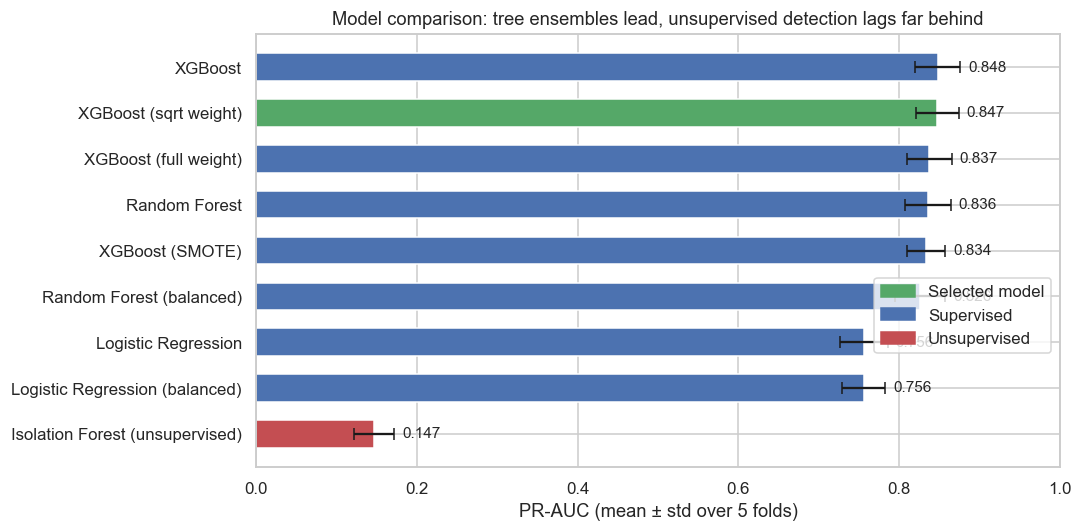

In [9]:
# Summary table
results_df = pd.DataFrame(cv_results).set_index("Model")
results_df = results_df.sort_values("PR-AUC", ascending=False)

display_cols = ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "CV time (s)"]
summary_table = results_df[display_cols].copy()
for m in ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]:
    summary_table[m] = (results_df[m].map("{:.3f}".format) + " ± "
                        + results_df[f"{m}_std"].map("{:.3f}".format))
summary_table["CV time (s)"] = results_df["CV time (s)"].round(1)
summary_table.to_csv(os.path.join(FIG_DIR, "table_cv_results.csv"))
print("5-fold cross-validation results (mean ± std), sorted by PR-AUC:\n")
display(summary_table)

# Chart: PR-AUC with error bars, supervised vs unsupervised coloured separately
plot_df = results_df.sort_values("PR-AUC")
colors = ["#C44E52" if "Isolation" in name else
          "#55A868" if name == "XGBoost (sqrt weight)" else "#4C72B0"
          for name in plot_df.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_df.index, plot_df["PR-AUC"], xerr=plot_df["PR-AUC_std"],
        color=colors, capsize=4, height=0.6)
for i, (value, std) in enumerate(zip(plot_df["PR-AUC"], plot_df["PR-AUC_std"])):
    ax.text(value + std + 0.01, i, f"{value:.3f}", va="center", fontsize=10)
ax.set_xlim(0, 1)
ax.set_xlabel("PR-AUC (mean ± std over 5 folds)")
ax.set_title("Model comparison: tree ensembles lead, unsupervised detection lags far behind")

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#55A868", label="Selected model"),
                   Patch(color="#4C72B0", label="Supervised"),
                   Patch(color="#C44E52", label="Unsupervised")],
                 loc="center right", bbox_to_anchor=(1.0, 0.35))

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_model_comparison.png"))
plt.show()

### 7. Decision Threshold Tuning

A classifier outputs a fraud probability; the decision threshold turns it into an alert. The default of 0.5 is arbitrary, so this step tests whether another threshold gives a better trade-off for the selected model, XGBoost (sqrt weight).

To avoid tuning on the test set, threshold selection uses **out-of-fold predictions**: each training transaction is scored by a model that never saw it during 5-fold cross-validation. The threshold is chosen to maximise the **F2 score**, which weights recall twice as heavily as precision, because a missed fraud (a direct financial loss) costs more than a false alert (a short analyst review).

F2-optimal threshold: 0.386
  Precision 0.868 | Recall 0.839 | F1 0.853 | F2 0.844

Threshold trade-off on out-of-fold predictions (378 frauds):


,Alerts,Frauds caught,False alerts,Precision,Recall
Threshold,,,,,
0.1000,482,322,160,0.6680,0.8519
0.2000,410,319,91,0.7780,0.8439
0.3000,380,317,63,0.8342,0.8386
0.5000,351,314,37,0.8946,0.8307
0.7000,336,307,29,0.9137,0.8122
0.9000,314,298,16,0.9490,0.7884


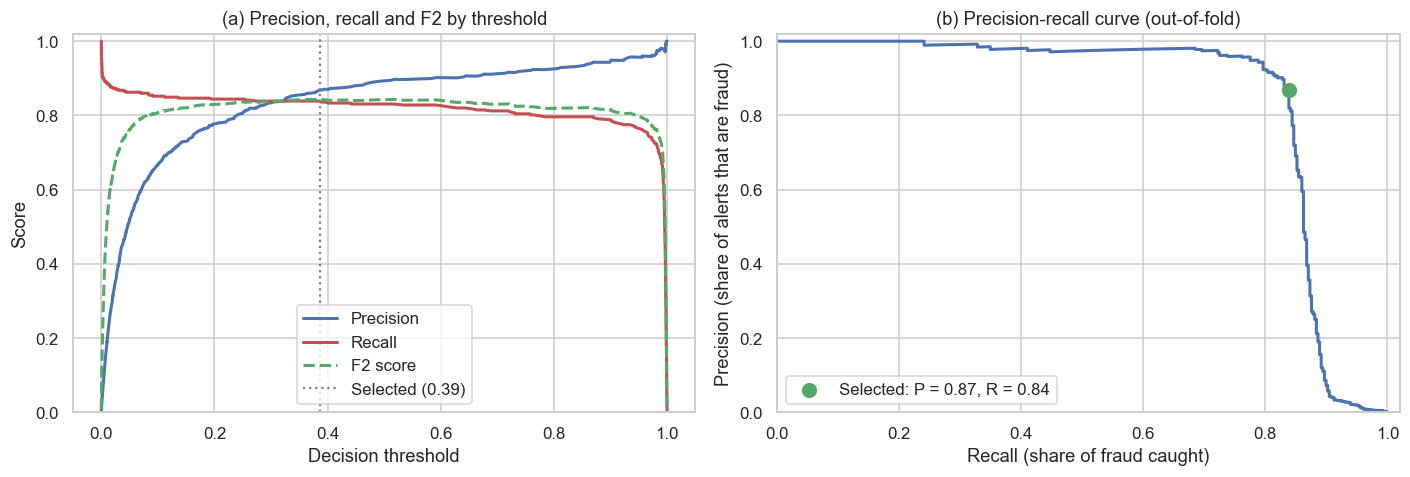

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

FINAL_PARAMS = dict(XGB_PARAMS, scale_pos_weight=np.sqrt(SPW))

# Out-of-fold fraud probabilities for every training transaction
oof_proba = cross_val_predict(xgb.XGBClassifier(**FINAL_PARAMS), X_train, y_train,
                              cv=CV, method="predict_proba", n_jobs=1)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
precision, recall = precision[:-1], recall[:-1]          # align with thresholds
f1 = 2 * precision * recall / (precision + recall + 1e-12)
f2 = 5 * precision * recall / (4 * precision + recall + 1e-12)
best = np.argmax(f2)
BEST_THRESHOLD = float(thresholds[best])

print(f"F2-optimal threshold: {BEST_THRESHOLD:.3f}")
print(f"  Precision {precision[best]:.3f} | Recall {recall[best]:.3f} | "
      f"F1 {f1[best]:.3f} | F2 {f2[best]:.3f}")

# Trade-off at a range of thresholds
rows = []
for t in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    alerts = oof_proba >= t
    tp = (alerts & (y_train == 1)).sum()
    rows.append({"Threshold": t, "Alerts": int(alerts.sum()),
                 "Frauds caught": int(tp), "False alerts": int(alerts.sum() - tp),
                 "Precision": tp / alerts.sum(), "Recall": tp / y_train.sum()})
tradeoff = pd.DataFrame(rows).set_index("Threshold")
print(f"\nThreshold trade-off on out-of-fold predictions ({y_train.sum()} frauds):")
display(tradeoff)

# Plot: precision and recall against threshold
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(thresholds, precision, label="Precision", color="#4C72B0", linewidth=2)
axes[0].plot(thresholds, recall, label="Recall", color="#C44E52", linewidth=2)
axes[0].plot(thresholds, f2, label="F2 score", color="#55A868", linewidth=2, linestyle="--")
axes[0].axvline(BEST_THRESHOLD, color="grey", linestyle=":", label=f"Selected ({BEST_THRESHOLD:.2f})")
axes[0].set_xlabel("Decision threshold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.02)
axes[0].set_title("(a) Precision, recall and F2 by threshold")
axes[0].legend(loc="lower center")

axes[1].plot(recall, precision, color="#4C72B0", linewidth=2)
axes[1].scatter(recall[best], precision[best], color="#55A868", s=80, zorder=5,
                label=f"Selected: P = {precision[best]:.2f}, R = {recall[best]:.2f}")
axes[1].set_xlabel("Recall (share of fraud caught)")
axes[1].set_ylabel("Precision (share of alerts that are fraud)")
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)
axes[1].set_title("(b) Precision-recall curve (out-of-fold)")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig6_threshold_tuning.png"))
plt.show()

### 8. Final Evaluation on the Held-Out Test Set

This step trains the selected model, XGBoost (sqrt weight), on the full training set and evaluates it **once** on the untouched test set (56,746 transactions, 95 frauds), using the threshold selected in the previous step. This is the unbiased estimate of real-world performance reported in the report.

Results at the default 0.5 threshold are shown alongside for comparison. Scoring latency is also measured, because a deployed fraud model must decide within the time a card payment takes to authorise.

Training time: 21.1 s on 226,980 transactions
Scoring latency: 0.0047 ms per transaction (batch)

Test PR-AUC:  0.819
Test ROC-AUC: 0.982



,Frauds caught (TP),Frauds missed (FN),False alerts (FP),Precision,Recall,F1,F2
Threshold,,,,,,,
Tuned (0.386),74,21,13,0.8506,0.7789,0.8132,0.7923
Default (0.500),73,22,9,0.8902,0.7684,0.8249,0.7900



Classification report at the tuned threshold:
              precision    recall  f1-score   support

  Legitimate      1.000     1.000     1.000     56651
       Fraud      0.851     0.779     0.813        95

    accuracy                          0.999     56746
   macro avg      0.925     0.889     0.906     56746
weighted avg      0.999     0.999     0.999     56746



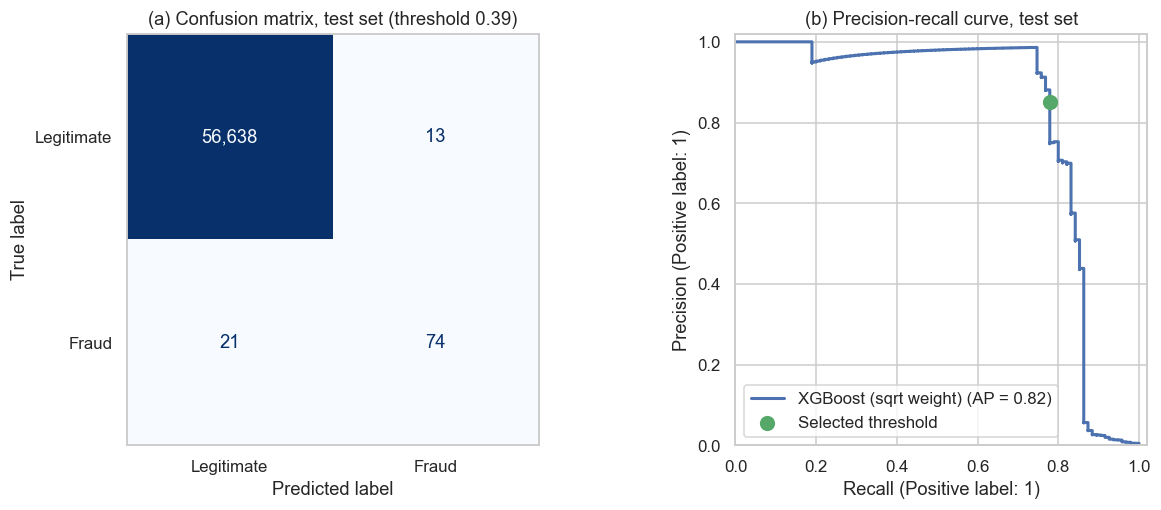

In [11]:
from sklearn.metrics import (confusion_matrix, classification_report, fbeta_score,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

# Train the final model on the full training set
start = time.time()
final_model = xgb.XGBClassifier(**FINAL_PARAMS).fit(X_train, y_train)
train_time = time.time() - start

# Score the test set and measure latency
start = time.time()
test_proba = final_model.predict_proba(X_test)[:, 1]
latency_ms = (time.time() - start) / len(X_test) * 1000

print(f"Training time: {train_time:.1f} s on {len(X_train):,} transactions")
print(f"Scoring latency: {latency_ms:.4f} ms per transaction (batch)\n")
print(f"Test PR-AUC:  {average_precision_score(y_test, test_proba):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.3f}\n")

# Metrics at the tuned and default thresholds
test_rows = []
for label, t in [(f"Tuned ({BEST_THRESHOLD:.3f})", BEST_THRESHOLD), ("Default (0.500)", 0.5)]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    test_rows.append({"Threshold": label, "Frauds caught (TP)": tp, "Frauds missed (FN)": fn,
                      "False alerts (FP)": fp, "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                      "F2": fbeta_score(y_test, pred, beta=2)})
test_table = pd.DataFrame(test_rows).set_index("Threshold")
test_table.to_csv(os.path.join(FIG_DIR, "table_test_results.csv"))
display(test_table)

test_pred = (test_proba >= BEST_THRESHOLD).astype(int)
print("\nClassification report at the tuned threshold:")
print(classification_report(y_test, test_pred, target_names=["Legitimate", "Fraud"], digits=3))

# Plots: confusion matrix and test precision-recall curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Legitimate", "Fraud"],
    cmap="Blues", colorbar=False, values_format=",", ax=axes[0])
axes[0].set_title(f"(a) Confusion matrix, test set (threshold {BEST_THRESHOLD:.2f})")
axes[0].grid(False)

PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[1], color="#4C72B0",
                                        name="XGBoost (sqrt weight)", linewidth=2)
axes[1].scatter(recall_score(y_test, test_pred), precision_score(y_test, test_pred),
                color="#55A868", s=80, zorder=5, label="Selected threshold")
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)
axes[1].set_title("(b) Precision-recall curve, test set")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig7_test_evaluation.png"))
plt.show()

### 9. Model Explainability with SHAP

A fraud model that cannot explain its decisions is hard to trust, audit or challenge. Under UK GDPR (Article 22), customers affected by automated decisions have rights to meaningful information about the logic involved. This step uses SHAP (SHapley Additive exPlanations), which assigns each feature a contribution to each individual prediction based on cooperative game theory (Lundberg and Lee, 2017).

Two views are produced on a sample of the test set (all 95 frauds plus 2,000 legitimate transactions):

1. **Global explanation (beeswarm plot):** which features drive fraud predictions across all transactions, and in which direction.
2. **Local explanation (waterfall plot):** why one specific transaction was flagged. This is the kind of explanation a fraud analyst would see when reviewing an alert.

SHAP values are in log-odds units: positive values push a transaction towards fraud, negative values towards legitimate.

Ten most influential features (mean |SHAP|, log-odds):
V14   1.3520
V4    1.0660
V12   0.6210
V10   0.5330
V8    0.3640
V11   0.3120
V19   0.2500
V3    0.2300
V26   0.2060
V22   0.1980


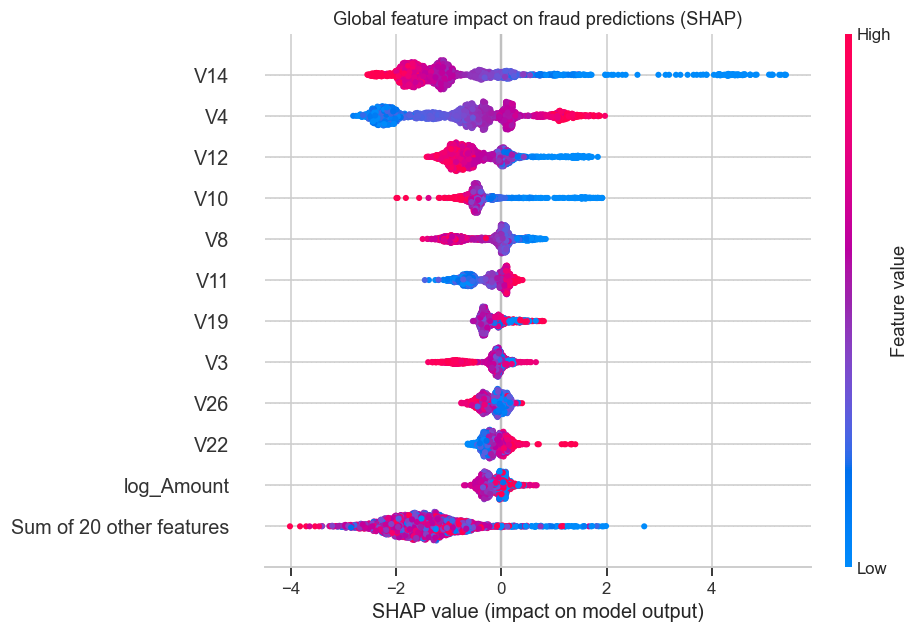


Explained transaction: true class = fraud, predicted fraud probability = 0.952


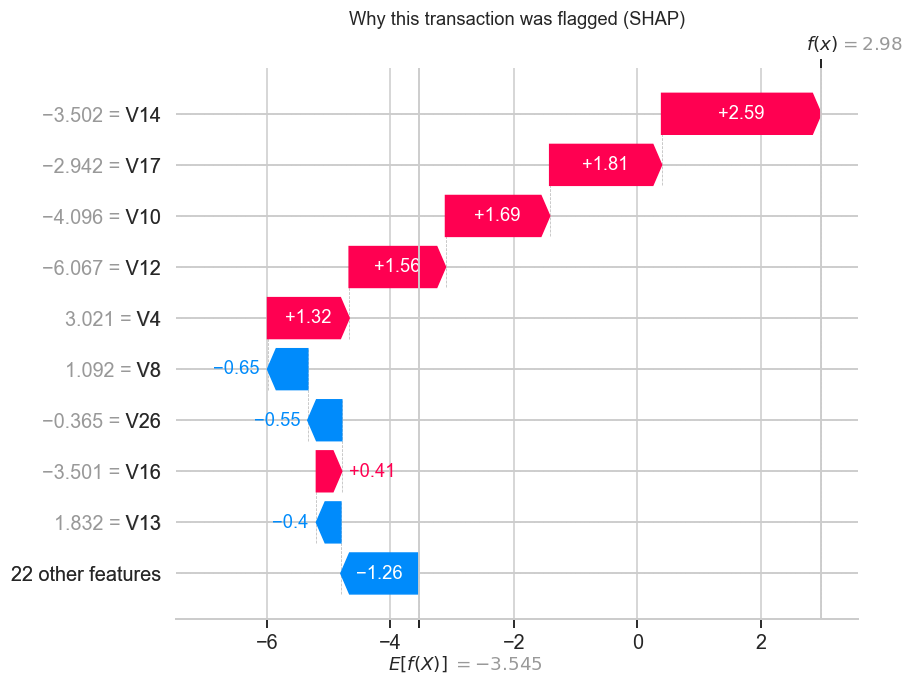

In [12]:
# Explanation sample: all test frauds + 2,000 random legitimate transactions
shap_sample = pd.concat([X_test[y_test == 1],
                         X_test[y_test == 0].sample(2000, random_state=RANDOM_STATE)])
shap_labels = y_test.loc[shap_sample.index]

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(shap_sample)

# Global importance: mean absolute SHAP value per feature
importance = pd.Series(np.abs(shap_values.values).mean(axis=0),
                       index=FEATURES).sort_values(ascending=False)
print("Ten most influential features (mean |SHAP|, log-odds):")
print(importance.head(10).round(3).to_string())

# (a) Global explanation: beeswarm
plt.figure()
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("Global feature impact on fraud predictions (SHAP)", fontsize=12)
plt.savefig(os.path.join(FIG_DIR, "fig8_shap_global.png"))
plt.show()

# (b) Local explanation: a correctly flagged fraud with a high, typical-alert score
sample_proba = final_model.predict_proba(shap_sample)[:, 1]
fraud_positions = np.where(shap_labels.values == 1)[0]
case = fraud_positions[np.argmin(np.abs(sample_proba[fraud_positions] - 0.95))]
print(f"\nExplained transaction: true class = fraud, "
      f"predicted fraud probability = {sample_proba[case]:.3f}")

plt.figure()
shap.plots.waterfall(shap_values[case], max_display=10, show=False)
plt.title("Why this transaction was flagged (SHAP)", fontsize=12)
plt.savefig(os.path.join(FIG_DIR, "fig9_shap_local.png"))
plt.show()

### 10. Saving the Model for Cloud Deployment

This step packages everything the Azure Machine Learning endpoint needs:

1. **The trained model** in XGBoost's native JSON format, which is portable across library versions.
2. **Model metadata**: feature order, decision threshold, hyperparameters, test metrics and library versions, so the deployed model is fully documented and reproducible.
3. **A sample request**: six raw transactions (three fraud, three legitimate) in the format the endpoint will accept, for testing in Phase 4.

The endpoint receives **raw** transactions (`Time`, `V1`–`V28`, `Amount`) and applies the same preprocessing as training. To guard against **training-serving skew**, the most common cause of silent failure in deployed models, this step rebuilds the raw test set, runs it through the deployment preprocessing function, and checks that the predictions are identical to those produced during evaluation.

In [14]:
from datetime import datetime, timezone
from sklearn.model_selection import train_test_split

# 1. Save the model in portable JSON format
MODEL_PATH = os.path.join(MODEL_DIR, "fraud_xgb_model.json")
final_model.save_model(MODEL_PATH)
scaler = joblib.load(os.path.join(MODEL_DIR, "amount_scaler.joblib"))


# 2. Deployment preprocessing: raw transaction -> model features (same steps as Notebook 1)
def preprocess_raw(raw_df):
    out = raw_df.copy()
    hour = (out["Time"] // 3600) % 24
    out["log_Amount"] = scaler.transform(
        pd.DataFrame({"log_Amount": np.log1p(out["Amount"])}))[:, 0]
    out["Hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["Hour_cos"] = np.cos(2 * np.pi * hour / 24)
    return out[FEATURES]


# 3. Training-serving skew check: rebuild the raw test set with the same split and seed
raw = pd.read_csv(os.path.join("data", "creditcard.csv"))
raw = raw.drop_duplicates(keep="first").reset_index(drop=True)
_, raw_test, _, raw_y_test = train_test_split(
    raw.drop(columns="Class"), raw["Class"], test_size=0.20,
    stratify=raw["Class"], random_state=RANDOM_STATE)

reloaded = xgb.XGBClassifier()
reloaded.load_model(MODEL_PATH)
serving_proba = reloaded.predict_proba(preprocess_raw(raw_test))[:, 1]
max_diff = np.abs(serving_proba - test_proba).max()
print(f"Training-serving skew check: max prediction difference = {max_diff:.2e}")
assert max_diff < 1e-6, "Deployment preprocessing does not match training!"
print("Passed: raw-input deployment path reproduces evaluation predictions exactly.\n")

# 4. Model metadata
pred = (test_proba >= BEST_THRESHOLD).astype(int)
metadata = {
    "model_name": "fraud-xgb-sqrt-weight",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "algorithm": "XGBoost classifier, scale_pos_weight = sqrt(legit/fraud)",
    "raw_input_columns": ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"],
    "model_features": FEATURES,
    "decision_threshold": round(BEST_THRESHOLD, 4),
    "hyperparameters": {k: (float(v) if isinstance(v, (np.floating, float)) else v)
                        for k, v in FINAL_PARAMS.items()},
    "training_rows": int(len(X_train)),
    "test_metrics": {
        "pr_auc": round(float(average_precision_score(y_test, test_proba)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, test_proba)), 4),
        "precision": round(float(precision_score(y_test, pred)), 4),
        "recall": round(float(recall_score(y_test, pred)), 4),
        "f1": round(float(f1_score(y_test, pred)), 4),
    },
    "library_versions": {"python": sys.version.split()[0], "xgboost": xgb.__version__,
                         "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                         "numpy": np.__version__},
}
with open(os.path.join(MODEL_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# 5. Sample request: 3 frauds + 3 legitimate raw transactions from the test set
sample_idx = (list(raw_test[raw_y_test == 1].sample(3, random_state=RANDOM_STATE).index)
              + list(raw_test[raw_y_test == 0].sample(3, random_state=RANDOM_STATE).index))
sample = raw_test.loc[sample_idx]
with open(os.path.join(MODEL_DIR, "sample_request.json"), "w") as f:
    json.dump({"data": sample.to_dict(orient="records")}, f, indent=2)

expected = pd.DataFrame({"true_class": raw_y_test.loc[sample_idx].values,
                         "fraud_probability": reloaded.predict_proba(preprocess_raw(sample))[:, 1]})
expected["flagged"] = expected["fraud_probability"] >= BEST_THRESHOLD
expected.to_csv(os.path.join(MODEL_DIR, "sample_expected_output.csv"), index=False)
print("Expected endpoint output for the sample request:")
display(expected.round(4))

print("\nDeployment artefacts saved:")
for name in ["fraud_xgb_model.json", "amount_scaler.joblib", "model_metadata.json",
             "sample_request.json", "sample_expected_output.csv"]:
    path = os.path.join(MODEL_DIR, name)
    print(f"  {path}  ({os.path.getsize(path) / 1024:.1f} KB)")

Training-serving skew check: max prediction difference = 0.00e+00
Passed: raw-input deployment path reproduces evaluation predictions exactly.

Expected endpoint output for the sample request:


,true_class,fraud_probability,flagged
0,1,0.0013,False
1,1,0.9978,True
2,1,0.9726,True
3,0,0.0001,False
4,0,0.0001,False
5,0,0.0000,False



Deployment artefacts saved:
  models\fraud_xgb_model.json  (555.8 KB)
  models\amount_scaler.joblib  (0.9 KB)
  models\model_metadata.json  (1.6 KB)
  models\sample_request.json  (5.8 KB)
  models\sample_expected_output.csv  (0.2 KB)
